In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

In [2]:
N = 100
X = np.random.random(N) * 6 - 3
y = 0.5 * X - 1 + np.random.randn(N) * 0.5

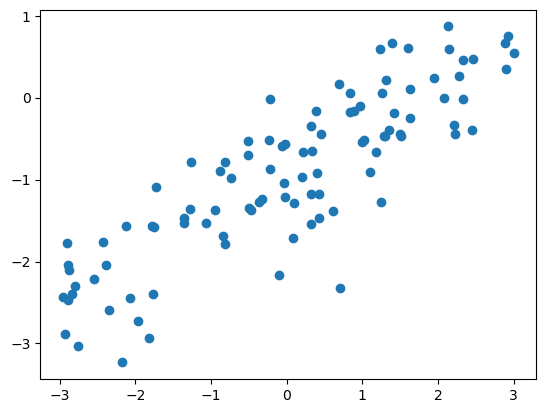

In [3]:
plt.scatter(X, y);

In [4]:
# build model
# HOMEWORK
i = Input(shape = (1,))
x = Dense(1)(i)
model = Model(i, x)          

In [5]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 1)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(loss='mse', optimizer=Adam(learning_rate=0.1), metrics=['mae'])
r = model.fit(X.reshape(-1,1), y, epochs=200, batch_size=32,)

Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 13.1065 - mae: 2.9608 
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 8.5731 - mae: 2.4053
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 5.2759 - mae: 1.8927 
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3.0272 - mae: 1.4339 
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.5582 - mae: 1.0371
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7105 - mae: 0.6946
Epoch 7/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3332 - mae: 0.4613
Epoch 8/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2715 - mae: 0.4172
Epoch 9/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3238 - mae: 0.4677 
Epoch 10/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3940 - mae: 0.5209 
Epoch 11/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4089 - mae: 0.5304 
Epoch 12/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3739 - mae: 0.5075 
Epoch 13/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/s

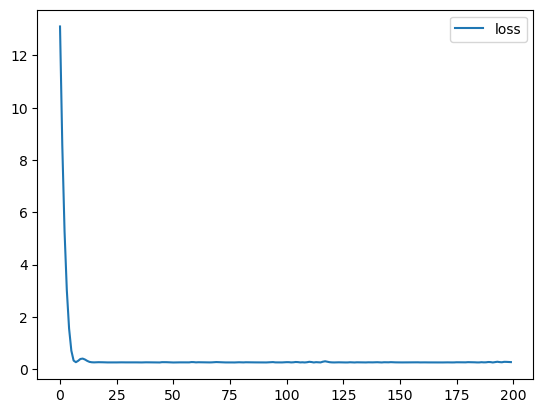

In [14]:
plt.plot(r.history['loss'], label='loss')
plt.legend()

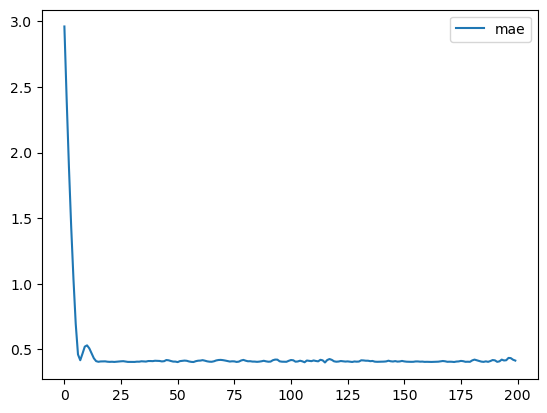

In [15]:
plt.plot(r.history['mae'], label='mae')
plt.legend()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


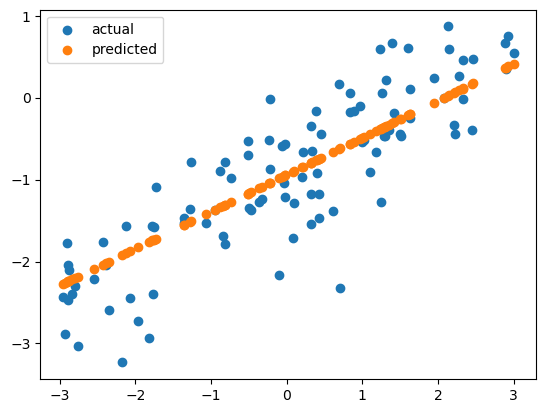

In [17]:
pred = model.predict(X)
plt.scatter(X, y, label='actual')
plt.scatter(X, pred, label='predicted')
plt.legend()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


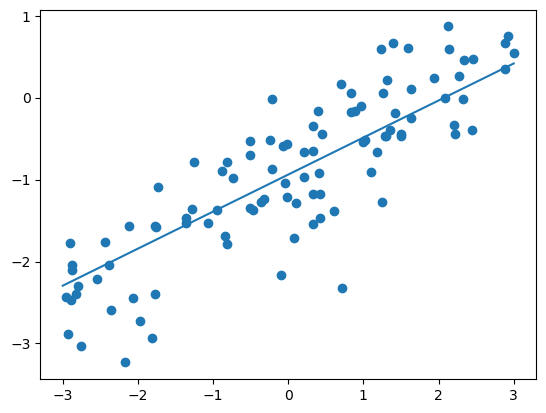

In [21]:
# Make predictions
Xtest = np.linspace(-3, 3, 20)#.reshape(-1, 1)
ptest = model.predict(Xtest)

plt.scatter(X, y)
plt.plot(Xtest, ptest);

In [22]:
model.layers

[<InputLayer name=input_layer, built=True>, <Dense name=dense, built=True>]

In [23]:
model.layers[1].get_weights()

[array([[0.45192954]], dtype=float32), array([-0.93885845], dtype=float32)]

![](https://deeplearningcourses.com/notebooks_v3_pxl?sc=MJHxClvYWOEUA8PFd__U7w&n=Linear+Regression+%28Warmup+%26+Syntax%29)